# HYOPE 감정 분류기 학습 노트북

KoELECTRA-v3를 AI Hub **노년층 대상 감성 분류** 데이터로 파인튜닝해
6종 감정(분노/기쁨/불안/당황/슬픔/상처) 분류기를 만든다.
학습된 모델은 `hyope-ai-server`에서 OpenAI(GPT) 분석 점수를 보정하는 참고용 플래깅에 쓰인다
(`AI_model_research.md` 참고).

## 워크플로우

1. **데이터 로딩 & EDA** — AI Hub + KOTE + KorEmpatheticDialogues, 레이블 분포 확인
2. **분할** — AI Hub에서 보류 테스트셋 10%를 먼저 떼고, 나머지 + 공개 데이터로 학습/검증
3. **학습** — `train/` 모듈 재사용, RTX 3070 Ti 기준 fp16
4. **평가** — 보류 테스트셋 분류 리포트 + 혼동 행렬 + 오류 분석
5. **추론 데모** — 노인 발화 예시 + 무레이블 test.csv 예측

## 알아둘 것

- `emotionClassification_test.zip`의 `test.csv`는 **레이블이 없다** (제출용 분할).
  그래서 채점 가능한 테스트셋은 train.csv에서 계층화 분할로 직접 만든다.
- 보류셋은 **AI Hub 데이터에서만** 뗀다 — 우리가 재고 싶은 건 노인 발화 도메인 성능이고,
  KOTE/KorEmpatheticDialogues는 학습 보강용이기 때문.
- `train/train.py`의 CLI 학습은 AI Hub 전체를 쓰므로, 그걸로 학습한 모델을
  보류셋으로 평가하면 점수가 부풀려진다. 정직한 평가는 이 노트북 방식으로 학습했을 때만 유효.

## 사전 준비

```bash
pip install -r ../requirements.txt
pip install jupyter matplotlib pandas   # 노트북 전용 의존성
```

In [1]:
!pwd

/home/sean429/HYOPE/hyope-ai/notebooks


In [2]:
!pip install -r ../requirements.txt


[notice] A new release of pip is available: 24.0 -> 26.2
[notice] To update, run: pip install --upgrade pip


In [3]:
import random
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import torch

# train/ 모듈 임포트 경로 (노트북은 notebooks/ 에서 실행된다고 가정)
TRAIN_DIR = Path.cwd().parent / "train"
sys.path.insert(0, str(TRAIN_DIR))

# train/ 모듈을 고친 뒤 이 셀만 다시 돌리면 파이썬이 sys.modules에 캐시된
# 옛 코드를 그대로 쓴다(ImportError: cannot import name ... 이 그때 난다).
# 커널을 재시작하지 않아도 되게 강제로 다시 읽는다.
import importlib
for _m in ["config", "label_mapper", "data_loader", "train", "evaluate", "predict"]:
    if _m in sys.modules:
        importlib.reload(sys.modules[_m])

from config import ID2LABEL, LABEL2ID, LABELS, TrainConfig
from data_loader import (
    load_aihub_data,
    load_empathetic_data,
    load_kote_data,
    load_somatic_seed,
    load_somatic_negatives,
    _cap_per_label,
    _drop_too_short,
    resolve_somatic_conflicts,
    resolve_somatic_conflicts,
)
from evaluate import split_aihub_holdout
from train import EmotionDataset, WeightedTrainer, compute_metrics

config = TrainConfig()
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

random.seed(config.seed)
np.random.seed(config.seed)
torch.manual_seed(config.seed)

print(f"device: {DEVICE}")
if DEVICE == "cuda":
    print(f"GPU: {torch.cuda.get_device_name(0)}")
print(f"레이블: {LABELS}")

/home/sean429/HYOPE/hyope-ai-server/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


device: cuda
GPU: NVIDIA GeForce RTX 3070 Ti
레이블: ['우울', '불안', '분노', '긍정', '신체불편']


## 1. 데이터 로딩

세 소스를 따로 로딩해 규모를 확인한다.

| 소스 | 성격 | 용도 |
|---|---|---|
| AI Hub 노년층 감성 분류 | 노인-챗봇 대화, 6종 레이블 원본 | 핵심 학습 데이터 + 보류 테스트셋 |
| KOTE | 44종 → 6종 매핑 | 학습 보강 |
| KorEmpatheticDialogues | 32종 → 6종 매핑 | 학습 보강 |

In [4]:
aihub_samples = load_aihub_data(config)
kote_samples = load_kote_data() if config.use_kote else []
empathetic_samples = load_empathetic_data() if config.use_empathetic else []
somatic_samples = load_somatic_seed(config) if config.use_somatic_seed else []
negative_samples = load_somatic_negatives(config) if config.use_somatic_seed else []

# 보조 소스 상한 — build_dataset()에 있는 것과 같은 처리를 여기서도 해줘야 한다.
# 이 노트북은 build_dataset()을 쓰지 않고 소스를 직접 불러 pool을 만들기 때문에,
# 빠뜨리면 KOTE 39,355건이 그대로 들어가 클래스 불균형이 67:1이 된다.
# 소스마다 깨진 행의 모양이 달라 로딩 후 공통으로 최소 길이를 건다
kote_samples = _drop_too_short(kote_samples, "KOTE")
empathetic_samples = _drop_too_short(empathetic_samples, "KorEmpathetic")

_cap = config.max_per_label_per_aux_source
kote_samples = _cap_per_label(kote_samples, _cap, config.seed, "KOTE")
empathetic_samples = _cap_per_label(empathetic_samples, _cap, config.seed, "KorEmpathetic")

sources = {
    "AI Hub": aihub_samples,
    "KOTE": kote_samples,
    "KorEmpathetic": empathetic_samples,
    "신체불편 시드": somatic_samples,
    "긍정-신체정상": negative_samples,
}

[AI Hub] 8537행 로드 (5종 매핑 제외 1613행)
[AI Hub] → 38531건으로 펼침
[KOTE] 39355건 로드


[KorEmpathetic] 15624건 로드
[신체불편] 시드 69건
[신체불편] 검수 완료 추출 후보 318건
[신체불편] 검수 완료 LLM 생성분 439건
[신체불편] 최종 826건
[긍정-신체정상] 193건 로드
[KorEmpathetic] 6자 미만 33건 제외
[KOTE] 라벨당 상한 2,000건 적용 — 32,870건 제외
[KorEmpathetic] 라벨당 상한 2,000건 적용 — 7,591건 제외


## 2. EDA — 레이블 분포와 텍스트 길이

In [5]:
!pip install matplotlib -q


[notice] A new release of pip is available: 24.0 -> 26.2
[notice] To update, run: pip install --upgrade pip


In [6]:
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

# 한글 폰트 (Windows: Malgun Gothic / WSL·Linux: NanumGothic → sudo apt install fonts-nanum)
_available = {f.name for f in matplotlib.font_manager.fontManager.ttflist}
for _font in ["Malgun Gothic", "NanumGothic", "NanumBarunGothic", "AppleGothic"]:
    if _font in _available:
        plt.rcParams["font.family"] = _font
        break
else:
    print("경고: 한글 폰트를 찾지 못했습니다. 차트의 한글이 깨질 수 있습니다.")
plt.rcParams["axes.unicode_minus"] = False

# 차트 팔레트 — 단일 변수는 blue 하나, 소스 구분만 카테고리 3색 고정 순서
BLUE, AQUA, YELLOW = "#2a78d6", "#1baf7a", "#eda100"
CORAL, PLUM = "#e0544e", "#8b5fbf"
SOURCE_COLORS = {
    "AI Hub": BLUE, "KOTE": AQUA, "KorEmpathetic": YELLOW,
    "신체불편 시드": CORAL, "긍정-신체정상": PLUM,
}
INK, INK_2, MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, SURFACE = "#e1e0d9", "#fcfcfb"
BLUE_RAMP = LinearSegmentedColormap.from_list(
    "blue_ramp", [SURFACE, "#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"]
)


def style_axes(ax):
    ax.set_facecolor(SURFACE)
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)
    for side in ["left", "bottom"]:
        ax.spines[side].set_color(GRID)
    ax.tick_params(colors=MUTED, labelcolor=INK_2)

,AI Hub,KOTE,KorEmpathetic,신체불편 시드,긍정-신체정상,합계
우울,15422,2000,2000,0,0,19422
불안,8112,485,2000,0,0,10597
분노,7333,2000,2000,0,0,11333
긍정,7664,2000,2000,0,193,11857
신체불편,0,0,0,826,0,826


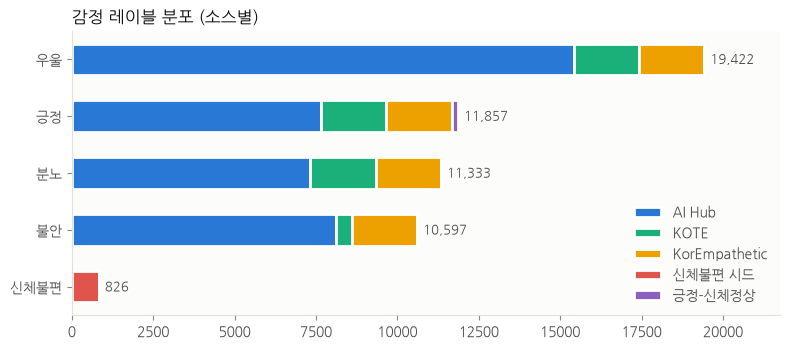

In [7]:
# 레이블 × 소스 건수 표 (차트의 표 뷰 역할도 겸함)
count_df = pd.DataFrame(
    {name: pd.Series([s["label"] for s in samples]).value_counts() for name, samples in sources.items()}
).fillna(0).astype(int)
count_df.index = [ID2LABEL[i] for i in count_df.index]
count_df = count_df.reindex(LABELS)
count_df["합계"] = count_df.sum(axis=1)
display(count_df)

# 소스별 누적 가로 막대 — 감정별 데이터 규모와 소스 구성을 한눈에
order = count_df["합계"].sort_values().index
fig, ax = plt.subplots(figsize=(8, 3.6))
left = np.zeros(len(order))
for name in sources:
    vals = count_df.loc[order, name].values
    ax.barh(order, vals, left=left, height=0.55, color=SOURCE_COLORS.get(name, MUTED),
            label=name, edgecolor="white", linewidth=2)
    left += vals
for i, total in enumerate(count_df.loc[order, "합계"]):
    ax.text(total + left.max() * 0.01, i, f"{total:,}", va="center", fontsize=9, color=INK_2)
style_axes(ax)
ax.set_title("감정 레이블 분포 (소스별)", color=INK, loc="left", fontsize=12)
ax.legend(frameon=False, loc="lower right", labelcolor=INK_2)
ax.set_xlim(0, left.max() * 1.12)
plt.tight_layout()
plt.show()

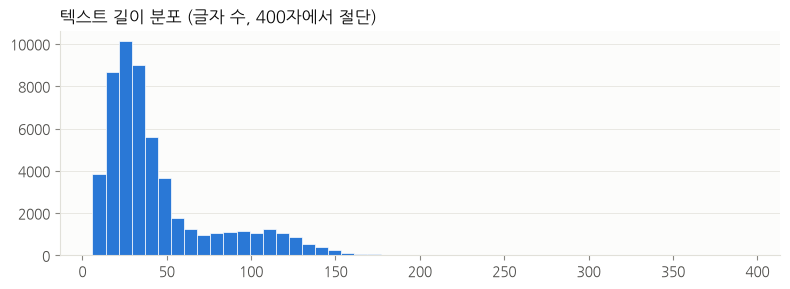

count    54035.0
mean        44.8
std         34.5
min          6.0
25%         22.0
50%         33.0
75%         51.0
max        394.0
dtype: float64
256자 초과 비율: 0.1%


In [8]:
# 텍스트 길이 분포 — max_length(256 토큰) 설정이 적절한지 확인
all_samples = aihub_samples + kote_samples + empathetic_samples + somatic_samples + negative_samples
lengths = pd.Series([len(s["text"]) for s in all_samples])

fig, ax = plt.subplots(figsize=(8, 3))
ax.hist(lengths.clip(upper=400), bins=50, color=BLUE, edgecolor="white", linewidth=0.5)
style_axes(ax)
ax.set_title("텍스트 길이 분포 (글자 수, 400자에서 절단)", color=INK, loc="left", fontsize=12)
ax.grid(axis="y", color=GRID, linewidth=0.5)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

print(lengths.describe().round(1))
print(f"256자 초과 비율: {(lengths > 256).mean():.1%}")

## 3. 데이터 분할

```
AI Hub ──┬── 90% ──┐
         └── 10% ──┼──────────────→ 보류 테스트셋 (학습에 절대 사용 안 함)
KOTE ──────────────┤
KorEmpathetic ─────┴── 학습 풀 ──┬── 90% → 학습셋
                                 └── 10% → 검증셋 (early stopping 기준)
```

분할 로직은 `train/evaluate.py`의 `split_aihub_holdout()`과 공유한다
(같은 seed → 같은 보류셋, CLI 평가와 노트북 평가가 일치).

In [9]:
from sklearn.model_selection import train_test_split

aihub_rest, test_samples = split_aihub_holdout(config)

# split_aihub_holdout()이 신체불편 시드와 긍정-신체정상까지 계층화 분할하므로
# aihub_rest에 이미 그 90%가 들어있다. somatic_samples/negative_samples를
# 여기서 또 더하면 중복 학습된다.
# build_dataset()과 같은 처리를 여기서도 해야 한다. 이 노트북은 build_dataset()을
# 쓰지 않고 소스를 직접 불러 pool을 만들기 때문에, 빠뜨리면 학습 데이터가
# build_dataset()과 달라진다.
pool = resolve_somatic_conflicts(aihub_rest + kote_samples + empathetic_samples,
                                 somatic_samples)
pool = _cap_per_label(pool, config.max_per_label, config.seed, "전체")
train_samples, val_samples = train_test_split(
    pool,
    test_size=config.val_ratio,
    random_state=config.seed,
    stratify=[s["label"] for s in pool],
)

print(f"학습: {len(train_samples):,}건 / 검증: {len(val_samples):,}건 / 보류 테스트: {len(test_samples):,}건")

[AI Hub] 8537행 로드 (5종 매핑 제외 1613행)
[신체불편] 시드 69건
[신체불편] 검수 완료 추출 후보 318건
[신체불편] 검수 완료 LLM 생성분 439건
[신체불편] 최종 826건
[긍정-신체정상] 193건 로드
[평가전용] 신체불편 143건 추가
[중복 정리] 보류셋에서 294건 제외 (라벨 상충 11종은 학습에서도 제외)
[전체] 라벨당 상한 8,000건 적용 — 17,057건 제외
학습: 29,468건 / 검증: 3,275건 / 보류 테스트: 3,775건


## 4. 학습

`train/train.py`와 같은 하이퍼파라미터에 fp16만 추가 (RTX 3070 Ti 기준 속도 ~2배).
저장 위치도 동일한 `model_output/` — `predict.py`와 FastAPI 통합 코드가 그대로 쓸 수 있다.

In [10]:
from transformers import (
    AutoModelForSequenceClassification,
    AutoTokenizer,
    EarlyStoppingCallback,
    TrainingArguments,
)

tokenizer = AutoTokenizer.from_pretrained(config.model_name)
model = AutoModelForSequenceClassification.from_pretrained(
    config.model_name,
    num_labels=len(LABELS),
    id2label=ID2LABEL,
    label2id=LABEL2ID,
)

train_dataset = EmotionDataset(train_samples, tokenizer, config.max_length)
val_dataset = EmotionDataset(val_samples, tokenizer, config.max_length)

training_args = TrainingArguments(
    output_dir=config.output_dir,
    num_train_epochs=config.epochs,
    per_device_train_batch_size=config.batch_size,
    per_device_eval_batch_size=config.batch_size,
    learning_rate=config.learning_rate,
    warmup_ratio=config.warmup_ratio,
    weight_decay=config.weight_decay,
    eval_strategy="epoch",
    save_strategy="epoch",
    save_total_limit=2,
    load_best_model_at_end=True,
    metric_for_best_model="f1_macro",
    greater_is_better=True,
    fp16=(DEVICE == "cuda"),
    logging_steps=100,
    seed=config.seed,
    report_to="none",
)

# 신체불편은 시드뿐이라 다른 라벨의 수십분의 1이다. 가중치 없이 학습하면 그 라벨을
# 아예 예측하지 않는 게 손실 함수상 이득이라 모델이 그렇게 수렴한다 — healthRisk
# 신호가 통째로 죽는다는 뜻이다.
from collections import Counter

class_weights = None
if config.use_class_weights:
    dist = Counter(s["label"] for s in train_samples)
    counts = torch.tensor([dist.get(i, 0) for i in range(len(LABELS))], dtype=torch.float)
    assert (counts > 0).all(), f"학습 데이터에 없는 라벨: {[LABELS[i] for i, c in enumerate(counts) if c == 0]}"
    class_weights = counts.mean() / counts
    print("클래스 가중치: " + ", ".join(f"{n}={w:.2f}" for n, w in zip(LABELS, class_weights.tolist())))

trainer = WeightedTrainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    compute_metrics=compute_metrics,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=config.early_stopping_patience)],
    class_weights=class_weights,
)

trainer.train()
trainer.save_model(config.output_dir)
tokenizer.save_pretrained(config.output_dir)
print(f"모델 저장 완료: {config.output_dir}")

Loading weights: 100%|██████████| 197/197 [00:00<00:00, 14037.31it/s]
[transformers] ElectraForSequenceClassification LOAD REPORT from: monologg/koelectra-base-v3-discriminator
Key                                               | Status     | 
--------------------------------------------------+------------+-
discriminator_predictions.dense.bias              | UNEXPECTED | 
discriminator_predictions.dense_prediction.weight | UNEXPECTED | 
discriminator_predictions.dense_prediction.bias   | UNEXPECTED | 
discriminator_predictions.dense.weight            | UNEXPECTED | 
classifier.out_proj.bias                          | MISSING    | 
classifier.dense.weight                           | MISSING    | 
classifier.dense.bias                             | MISSING    | 
classifier.out_proj.weight                        | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initial

클래스 가중치: 우울=0.82, 불안=0.82, 분노=0.82, 긍정=0.82, 신체불편=8.82


Epoch,Training Loss,Validation Loss,F1 Macro
1,0.833267,0.792547,0.659741
2,0.687568,0.722524,0.717293
3,0.520101,0.713037,0.731124
4,0.399642,0.758080,0.743454
5,0.313392,0.821254,0.743030


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  2.82it/s]

모델 저장 완료: /home/sean429/HYOPE/hyope-ai/model_output


## 5. 평가 — 보류 테스트셋

학습에 한 번도 쓰이지 않은 AI Hub 보류셋으로 채점한다.
CLI로도 같은 평가 가능: `cd ../train && python evaluate.py`

In [11]:
from evaluate import evaluate

eval_result = evaluate(config.output_dir, config)

[AI Hub] 8537행 로드 (5종 매핑 제외 1613행)
[신체불편] 시드 69건
[신체불편] 검수 완료 추출 후보 318건
[신체불편] 검수 완료 LLM 생성분 439건
[신체불편] 최종 826건
[긍정-신체정상] 193건 로드
[평가전용] 신체불편 143건 추가
[중복 정리] 보류셋에서 294건 제외 (라벨 상충 11종은 학습에서도 제외)


Loading weights: 100%|██████████| 201/201 [00:00<00:00, 3571.48it/s]


보류 테스트셋 3775건 평가 (device=cuda)
              precision    recall  f1-score   support

          우울     0.7033    0.5887    0.6409      1393
          불안     0.4865    0.6604    0.5603       739
          분노     0.5352    0.5697    0.5519       667
          긍정     0.8389    0.7427    0.7878       750
        신체불편     0.9224    0.9469    0.9345       226

    accuracy                         0.6514      3775
   macro avg     0.6973    0.7017    0.6951      3775
weighted avg     0.6712    0.6514    0.6562      3775



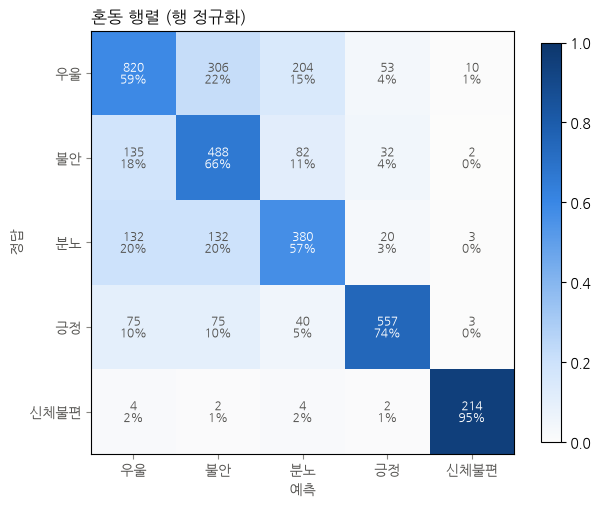

In [12]:
# 혼동 행렬 — 행 정규화(재현율 관점), 셀에 건수 표기
cm = eval_result["confusion"]
cm_norm = cm / cm.sum(axis=1, keepdims=True)

fig, ax = plt.subplots(figsize=(6.4, 5.6))
im = ax.imshow(cm_norm, cmap=BLUE_RAMP, vmin=0, vmax=1)
ax.set_xticks(range(len(LABELS)), LABELS)
ax.set_yticks(range(len(LABELS)), LABELS)
ax.set_xlabel("예측", color=INK_2)
ax.set_ylabel("정답", color=INK_2)
ax.tick_params(colors=MUTED, labelcolor=INK_2)
ax.set_title("혼동 행렬 (행 정규화)", color=INK, loc="left", fontsize=12)
for i in range(len(LABELS)):
    for j in range(len(LABELS)):
        text_color = "white" if cm_norm[i, j] > 0.5 else INK_2
        ax.text(j, i, f"{cm[i, j]}\n{cm_norm[i, j]:.0%}",
                ha="center", va="center", fontsize=8.5, color=text_color)
fig.colorbar(im, ax=ax, shrink=0.8)
plt.tight_layout()
plt.show()

In [13]:
# 오류 분석 — 모델이 높은 확신으로 틀린 사례부터 (레이블 매핑 문제나 데이터 노이즈 힌트)
err_df = pd.DataFrame({
    "텍스트": eval_result["texts"],
    "정답": [ID2LABEL[t] for t in eval_result["true"]],
    "예측": [r["emotion"] for r in eval_result["results"]],
    "확신도": [r["confidence"] for r in eval_result["results"]],
})
errors = err_df[err_df["정답"] != err_df["예측"]].sort_values("확신도", ascending=False)

print(f"오분류 {len(errors)}건 / 전체 {len(err_df)}건 ({len(errors) / len(err_df):.1%})")
with pd.option_context("display.max_colwidth", 80):
    display(errors.head(15))

# 가장 자주 헷갈리는 정답→예측 쌍
print(errors.groupby(["정답", "예측"]).size().sort_values(ascending=False).head(8))

오분류 1316건 / 전체 3775건 (34.9%)


,텍스트,정답,예측,확신도
2583,몸이 아파 움직이지도 못하는걸.,불안,신체불편,0.9985
3362,박 노인이 아파서 내가 모든 걸 그만두고 간병하기 시작했어.,우울,신체불편,0.9976
1613,귀에서 삐 소리 나는 건 없구먼,긍정,신체불편,0.9975
3624,요즘 심지어 허리도 아프거든.,분노,신체불편,0.9969
1154,허리가 꼿꼿한 나를 보고 자녀들이 보기 좋다고 말해줬어.,신체불편,긍정,0.9948
1965,정년퇴직하고 몸이 안 좋아서 고생하고 있어. 몸이 아프니 지난 삶을 돌아보게 되네. 생각해보니 고마운 사람들이 많아 감사하는 마음이야.,긍정,신체불편,0.9940
751,우리 손자들이 이제 막 말을 하기 시작해서 보고 있으면 얼마나 예쁜지 몰라.,우울,긍정,0.9937
2690,이젠 익숙해져서 그런지 외롭지도 않아.,우울,긍정,0.9927
2887,오늘 전화를 통해서 자식에게 항상 고맙다고 말해보려고.,불안,긍정,0.9924
1117,김 씨가 소개하는 건강 보조제들은 항상 효과가 좋아서 이번에도 하나 더 구매했어. 항상 나에게 좋은 제품들만 소개 해줘서 나도 김 씨에게...,분노,긍정,0.9921


정답  예측
우울  불안    306
    분노    204
불안  우울    135
분노  불안    132
    우울    132
불안  분노     82
긍정  우울     75
    불안     75
dtype: int64


## 6. 추론 데모

FastAPI 통합 시 사용할 `EmotionPredictor` 그대로 사용.

In [14]:
from predict import EmotionPredictor

predictor = EmotionPredictor(config.output_dir, device=DEVICE)

demo_texts = [
    "요즘 너무 외롭고 힘들어요. 아무것도 하기 싫어요.",
    "오늘 손주가 놀러와서 정말 기분이 좋았어요.",
    "약을 먹어야 하는데 자꾸 깜빡해서 걱정돼요.",
    "어젯밤에 잠을 통 못 잤어. 자꾸 이상한 소리가 들리는 것 같아서.",
    "아들이 전화 한 통을 안 해. 서운해 죽겠어.",
    "밥은 잘 먹었지. 반찬도 맛있게 해 먹었어.",
]
for text, result in zip(demo_texts, predictor.predict_batch(demo_texts)):
    top3 = sorted(result["scores"].items(), key=lambda x: -x[1])[:3]
    print(f"{result['emotion']} ({result['confidence']:.2f})  {text}")
    print(f"    상위 3: {', '.join(f'{k} {v:.2f}' for k, v in top3)}")

Loading weights: 100%|██████████| 201/201 [00:00<00:00, 3429.53it/s]

우울 (0.97)  요즘 너무 외롭고 힘들어요. 아무것도 하기 싫어요.
    상위 3: 우울 0.97, 불안 0.02, 분노 0.01
긍정 (0.99)  오늘 손주가 놀러와서 정말 기분이 좋았어요.
    상위 3: 긍정 0.99, 우울 0.00, 불안 0.00
불안 (0.94)  약을 먹어야 하는데 자꾸 깜빡해서 걱정돼요.
    상위 3: 불안 0.94, 분노 0.05, 우울 0.01
불안 (0.98)  어젯밤에 잠을 통 못 잤어. 자꾸 이상한 소리가 들리는 것 같아서.
    상위 3: 불안 0.98, 분노 0.01, 우울 0.00
분노 (0.93)  아들이 전화 한 통을 안 해. 서운해 죽겠어.
    상위 3: 분노 0.93, 우울 0.06, 불안 0.01
긍정 (0.99)  밥은 잘 먹었지. 반찬도 맛있게 해 먹었어.
    상위 3: 긍정 0.99, 우울 0.01, 분노 0.00


In [15]:
# 무레이블 test.csv 예측 미리보기 (채점 불가, 정성 확인용)
import csv
import io
import zipfile

with zipfile.ZipFile(Path(config.aihub_train_zip).parent / "emotionClassification_test.zip") as z:
    with z.open("test.csv") as f:
        rows = list(csv.DictReader(io.StringIO(f.read().decode("utf-8-sig"))))

test_texts = [
    " ".join(row[f"사람문장{i}"].strip() for i in range(1, 5) if row.get(f"사람문장{i}", "").strip())
    for row in rows[:10]
]
for text, result in zip(test_texts, predictor.predict_batch(test_texts)):
    print(f"{result['emotion']} ({result['confidence']:.2f})  {text[:70]}")

우울 (0.97)  나는 보험금을 받은 적이 없는데 아들이 위임장을 가지고 와서 보험금을 모두 가져갔다는 말을 들었어. 아들이 내게 말도 없이 위
불안 (0.73)  난 현재 한 친구녀석 때문에 꽤 힘든 것 같아. 맞아.한 친구녀석이 있는데 그 자식이 내 아들녀석을 나쁘게 보고있는 것 같아.
불안 (0.98)  치료를 너무 많이 받아서 얼굴이 갈수록 상하는 것 같아서 스트레스야. 너무 많은 치료를 받다 보니 먹는 약도 많아서 그런 것 
불안 (0.97)  모임을 가면 옷차림에 신경을 쓰게 되어서 스트레스를 받아. 은퇴 후에 남들한테 초라해 보이지는 않을지 불안해서 더 그러는 것 
우울 (0.86)  나에게 너무 화가 나 치매에 걸린 아내가 집을 나갔을 때 포기하려고 했어. 그런 생각을 했다는 나에게 스스로 밉고 화가 나는 
불안 (0.95)  내가 죽을 때까지 쓰고도 남을 것 같던 돈이 바닥났어. 그 돈만 믿고 흥청망청 살았는데 앞으로의 삶이 막막해서 불안해. 다행히
우울 (0.93)  자식들이 일찍 철들기 바라는 마음에 지원을 최소한만 해줬더니 성인이 되고 모두 나와 연락을 끊어버렸어. 그렇게 나와 연락까지 
불안 (0.98)  이번 달에는 아내에게 줄 생활비가 없어서 불안해. 이제 내 몸도 성치 않고 계속 돈을 벌어다 주는 것도 힘이 들어. 자식들에게
불안 (0.87)  친구가 얼마 전에 갑자기 쓰러져서 충격이야. 혹시 잘못된 거 아닐까 놀라서 가슴이 진정이 안 되더라고. 다행히 큰 병은 아니었
불안 (0.95)  지금 받은 대출도 다 못 갚았는데 치료비 때문에 대출을 또 받아야 하는지 고민이 되고 있어. 맞아. 되도록이면 받지 않았으면 


## 다음 단계

1. **FastAPI 통합** — `hyope-ai-server`에 `model_output/`을 복사(또는 경로 참조)하고:

   ```python
   # hyope-ai-server 쪽에서
   from predict import EmotionPredictor
   emotion_predictor = EmotionPredictor("./model_output")  # CPU로도 동작
   # /analyze-call에서 OpenAI(GPT) 분석 점수 옆에 참고용 감정 플래그로 추가
   ```

2. **개선 실험 아이디어**
   - 클래스 불균형 대응: 소수 레이블 가중 loss 또는 KOTE/Empathetic 샘플링 비율 조정
   - `config.use_kote / use_empathetic` on/off 비교 — 공개 데이터 보강이 AI Hub 보류셋 성능에 실제 도움이 되는지 확인
   - AI Hub **생성형AI 고령자 구술 데이터**(dataSetSn=71703) 승인 후 우울·불안 회귀 태스크 추가

3. **EXAONE QLoRA** — 로컬 8GB VRAM으로는 빠듯하므로 Colab Pro / RunPod 확보 후 별도 노트북으로
   (`AI_model_research.md` §3~4의 설정값 참고)